# AOG prediction: will a component fail within the next 30 flight cycles?

**Target grain of the modeling table: 1 row per (`component_id`, `flight_cycle`).**

**Prediction time:** right after flight cycle *t* lands. Known at that moment: sensor readings of cycles ≤ *t*, maintenance done in cycles < *t*, static aircraft/component attributes.

**Target `tgt_fail_30`:** 1 if the component has an **unscheduled** maintenance event in cycles *t+1 … t+30*, else 0.
Rows whose next 30 cycles are not fully observed and contain no failure are **censored** (label unknown) and are not used.

| Table | Grain (raw) |
|---|---|
| `fleet_info` | 1 row per `aircraft_id` (static: model, year, base, total flight hours) |
| `components` | 1 row per `component_id` (aircraft, type, installation date) |
| `sensor_readings` | 1 row per (`component_id`, `flight_cycle`): temperature, vibration, pressure |
| `maintenance_events` | 1 row per event: component, cycle/date, scheduled vs unscheduled |

Same structure as `maintenance.ipynb` (EDA → grain → validated joins → lag-safe features → model), with these changes:
- time axis is the **flight cycle per component**, not the calendar week;
- the target looks **30 cycles ahead** instead of "failure this week", so right-censoring has to be handled;
- sensor scales differ by component type (~3,000 PSI pump vs ~25 PSI bearing), so sensors are **normalised against each component's own healthy baseline**;
- with ~11 failures, evaluation is **grouped cross-validation by component** (no component in both train and validation), plus a component-level check: was each failure flagged, and how many cycles ahead?

In [25]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path(os.environ.get("AOG_DATA_DIR", "datasets/aog"))  # folder with the 4 challenge CSVs
HORIZON = 30          # the target looks this many cycles ahead
BASELINE_CYCLES = 10  # first cycles of each component life = its healthy baseline
WINDOWS = (5, 10)     # rolling windows (cycles) for trend features
SENSORS = ["temperature_celsius", "vibration_mm_s", "pressure_psi"]
SHORT = {s: s.split("_")[0][:4] for s in SENSORS}  # temp, vibr, pres

findings = []  # (table, issue, rows, decision)
def log(table, issue, rows, decision):
    findings.append((table, issue, int(rows), decision))
    print(f"[{table}] {issue}: {int(rows):,} -> {decision}")

## 0. Load
Each table is found by a keyword in its CSV file name. If the challenge builds the tables in memory instead,
replace this cell with `dfs = {"fleet": ..., "components": ..., "sensors": ..., "maint": ...}`.

In [26]:
TABLE_KEYWORDS = {"fleet": "fleet", "components": "component", "sensors": "sensor", "maint": "maint"}

def find_file(keyword):
    hits = sorted(p for p in DATA_DIR.glob("*.csv") if keyword in p.stem.lower())
    assert len(hits) == 1, f"expected 1 CSV matching '{keyword}' in {DATA_DIR}, found {[h.name for h in hits]}"
    return hits[0]

dfs = {}
for name, kw in TABLE_KEYWORDS.items():
    path = find_file(kw)
    dfs[name] = pd.read_csv(path)
    print(f"{name:<11} <- {path.name}: {dfs[name].shape[0]:,} rows x {dfs[name].shape[1]} columns")

fleet       <- fleet_info.csv: 20 rows x 5 columns
components  <- components.csv: 50 rows x 5 columns
sensors     <- sensor_readings.csv: 5,015 rows x 7 columns
maint       <- maintenance_events.csv: 199 rows x 8 columns


### Column names
Columns are snake-cased. If the challenge uses different names, map them in `RENAME` so the rest of the notebook works unchanged.
The scheduled/unscheduled column is detected automatically (the text column containing "unscheduled").

In [27]:
for df in dfs.values():
    df.columns = df.columns.str.strip().str.lower().str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")

# e.g. RENAME = {"sensors": {"cycle": "flight_cycle", "temp_c": "temperature_celsius"}}
RENAME = {}
for name, mapping in RENAME.items():
    dfs[name] = dfs[name].rename(columns=mapping)

REQUIRED = {
    "fleet": ["aircraft_id"],
    "components": ["component_id", "aircraft_id", "component_type"],
    "sensors": ["component_id", "flight_cycle", *SENSORS],
    "maint": ["component_id"],
}
for name, cols in REQUIRED.items():
    missing = set(cols) - set(dfs[name].columns)
    assert not missing, f"{name} is missing {missing}; add them to RENAME. Columns: {list(dfs[name].columns)}"

def is_text(s):
    return s.dtype == object or pd.api.types.is_string_dtype(s)

type_candidates = [c for c in dfs["maint"] if is_text(dfs["maint"][c])
                   and dfs["maint"][c].astype(str).str.lower().str.contains("unscheduled").any()]
type_candidates.sort(key=lambda c: "type" not in c)  # prefer a column called *type*
assert type_candidates, "no maintenance column contains 'unscheduled'"
EVENT_TYPE_COL = type_candidates[0]

# Parse date-like columns; count values that fail to parse
DATE_PAT = re.compile(r"(date|timestamp|datetime|_at$|^time$)")
for name, df in dfs.items():
    for c in [c for c in df if DATE_PAT.search(c)]:
        n_null = df[c].isna().sum()
        df[c] = pd.to_datetime(df[c], errors="coerce", format="mixed")
        if (bad := df[c].isna().sum() - n_null):
            log(name, f"Unparseable values in {c}", bad, "Set to NaT")

fleet, components, sensors, maint = (dfs[k] for k in ("fleet", "components", "sensors", "maint"))
TS_COL = next((c for c in sensors if DATE_PAT.search(c)), None)         # reading timestamp, if any
EV_DATE_COL = next((c for c in maint if DATE_PAT.search(c)), None)      # event date, if any
INSTALL_COL = next((c for c in components if "install" in c), None)     # installation date, if any
print(f"event type column: {EVENT_TYPE_COL} | reading timestamp: {TS_COL} | event date: {EV_DATE_COL} | install date: {INSTALL_COL}")
for name, df in dfs.items():
    print(f"{name}: {list(df.columns)}")

event type column: maintenance_type | reading timestamp: timestamp | event date: event_date | install date: installation_date
fleet: ['aircraft_id', 'aircraft_model', 'manufacture_year', 'base_airport', 'total_flight_hours']
components: ['component_id', 'aircraft_id', 'component_type', 'installation_date', 'status']
sensors: ['reading_id', 'component_id', 'flight_cycle', 'timestamp', 'temperature_celsius', 'vibration_mm_s', 'pressure_psi']
maint: ['event_id', 'component_id', 'flight_cycle', 'maintenance_type', 'action', 'downtime_hours', 'aircraft_id', 'event_date']


## 1. EDA
### Shapes and dtypes

In [28]:
for name, df in dfs.items():
    print(f"\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(df.dtypes.to_string())


fleet: 20 rows x 5 columns
aircraft_id             str
aircraft_model          str
manufacture_year      int64
base_airport            str
total_flight_hours    int64

components: 50 rows x 5 columns
component_id                    str
aircraft_id                     str
component_type                  str
installation_date    datetime64[us]
status                          str

sensors: 5,015 rows x 7 columns
reading_id                      int64
component_id                      str
flight_cycle                    int64
timestamp              datetime64[us]
temperature_celsius           float64
vibration_mm_s                float64
pressure_psi                  float64

maint: 199 rows x 8 columns
event_id                     int64
component_id                   str
flight_cycle               float64
maintenance_type               str
action                         str
downtime_hours             float64
aircraft_id                    str
event_date          datetime64[us]


### Null %

In [29]:
null_pct = pd.concat({n: df.isna().mean().mul(100).round(2) for n, df in dfs.items()},
                     names=["table", "column"]).rename("null_%")
null_pct[null_pct > 0].to_frame() if (null_pct > 0).any() else "no nulls"

null_%
table   column                     
sensors temperature_celsius    1.99
        vibration_mm_s         1.99
        pressure_psi           1.99
maint   flight_cycle           1.01

### Duplicates
Surrogate ids (unique per row, like `reading_id`) hide duplicates, so they are ignored in the full-row check.

In [30]:
KEYS = {"fleet": ["aircraft_id"], "components": ["component_id"], "sensors": ["component_id", "flight_cycle"], "maint": None}

def surrogate_ids(df, key):
    return [c for c in df if c.endswith("_id") and df[c].is_unique and c not in (key or [])]

pd.DataFrame({
    name: {
        "rows": len(df),
        "ignored_ids": ", ".join(surrogate_ids(df, KEYS[name])) or "-",
        "full_row_dups": df.drop(columns=surrogate_ids(df, KEYS[name])).duplicated().sum(),
        "key": ", ".join(KEYS[name]) if KEYS[name] else "-",
        "key_dups": df.duplicated(KEYS[name]).sum() if KEYS[name] else "-",
    }
    for name, df in dfs.items()
}).T

,rows,ignored_ids,full_row_dups,key,key_dups
fleet,20,-,0,aircraft_id,0
components,50,-,0,component_id,0
sensors,5015,reading_id,15,"component_id, flight_cycle",15
maint,199,event_id,0,-,-


### Categorical values
Raw labels, before any cleaning (look for case/whitespace variants).

In [31]:
for name, df in dfs.items():
    for c in [c for c in df if is_text(df[c])]:
        vc = df[c].value_counts(dropna=False)
        print(f"{name}.{c}: " + (str(vc.to_dict()) if len(vc) <= 15 else f"{len(vc)} unique"))

fleet.aircraft_id: 20 unique
fleet.aircraft_model: {'B737-800': 8, 'E190': 6, 'A320': 6}
fleet.base_airport: {'LIM': 8, 'BOG': 7, 'SCL': 5}
components.component_id: 50 unique
components.aircraft_id: 19 unique
components.component_type: {'bearing': 13, 'filter': 12, 'actuator': 11, 'hydraulic_pump': 10, 'valve': 4}
components.status: {'active': 39, 'replaced': 11}
sensors.component_id: 50 unique
maint.component_id: 51 unique
maint.maintenance_type: {'scheduled': 68, 'Scheduled': 60, 'SCHEDULED': 60, 'UNSCHEDULED ': 4, 'Unscheduled': 4, 'unscheduled': 3}
maint.action: {'inspection': 54, 'adjustment': 48, 'cleaning': 44, 'lubrication': 42, 'major_repair': 7, 'replacement': 4}
maint.aircraft_id: 19 unique


### Key relationships
Orphan keys, fan-out, and whether the event's aircraft matches the component's aircraft.

In [32]:
for child, child_name, parent, parent_name, key in [
    (components, "components", fleet, "fleet", "aircraft_id"),
    (sensors, "sensors", components, "components", "component_id"),
    (maint, "maint", components, "components", "component_id"),
]:
    n = (~child[key].isin(parent[key])).sum()
    print(f"{child_name}.{key} not in {parent_name}: {n:,}")

print("components without sensor readings:", (~components["component_id"].isin(sensors["component_id"])).sum())
print("components per aircraft:", components.groupby("aircraft_id").size().describe()[["min", "50%", "max"]].to_dict())
print("events per component:", maint.groupby("component_id").size().describe()[["min", "50%", "max"]].to_dict())

if "aircraft_id" in maint:
    ac_of_comp = maint["component_id"].map(components.set_index("component_id")["aircraft_id"])
    mismatch = (ac_of_comp.notna() & (ac_of_comp != maint["aircraft_id"])).sum()
    print("maint rows whose aircraft_id differs from the component's aircraft:", mismatch)
    if mismatch:
        log("maint", "aircraft_id differs from the component's aircraft", mismatch, "component_id is trusted; aircraft_id not used")

components.aircraft_id not in fleet: 0
sensors.component_id not in components: 0
maint.component_id not in components: 1
components without sensor readings: 0
components per aircraft: {'min': 1.0, '50%': 2.0, 'max': 5.0}
events per component: {'min': 1.0, '50%': 3.0, 'max': 9.0}
maint rows whose aircraft_id differs from the component's aircraft: 0


### Flight-cycle coverage per component

In [33]:
cyc = sensors.groupby("component_id")["flight_cycle"].agg(["min", "max", "nunique", "size"])
cyc["gaps"] = cyc["max"] - cyc["min"] + 1 - cyc["nunique"]
display(cyc.describe().T.round(1))
print("components with missing cycles:", (cyc["gaps"] > 0).sum())

if "flight_cycle" in maint:
    ev = maint.join(cyc[["min", "max"]], on="component_id")
    print("events with no flight_cycle:", maint["flight_cycle"].isna().sum())
    print("events outside the component's sensor cycle range:",
          ((ev["flight_cycle"] < ev["min"]) | (ev["flight_cycle"] > ev["max"])).sum())

,count,mean,std,min,25%,50%,75%,max
min,50.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
max,50.0,100.0,0.0,100.0,100.0,100.0,100.0,100.0
nunique,50.0,100.0,0.0,100.0,100.0,100.0,100.0,100.0
size,50.0,100.3,0.6,100.0,100.0,100.0,100.0,102.0
gaps,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


components with missing cycles: 0
events with no flight_cycle: 2
events outside the component's sensor cycle range: 0


### Timestamp order checks (only when the dates exist)

In [34]:
if INSTALL_COL and TS_COL:
    first_read = sensors.groupby("component_id")[TS_COL].min().rename("first_reading")
    chk = components.set_index("component_id").join(first_read)
    n = (chk[INSTALL_COL] > chk["first_reading"]).sum()
    print(f"components installed after their first sensor reading: {n}")
    if n:
        log("components", f"{INSTALL_COL} after first sensor reading", n,
            "Installation date likely overwritten by a later replacement; not used as a feature")
if INSTALL_COL and EV_DATE_COL:
    ev = maint.join(components.set_index("component_id")[INSTALL_COL], on="component_id")
    n = (ev[EV_DATE_COL] < ev[INSTALL_COL]).sum()
    print(f"events dated before the component's installation: {n}")
    if n:
        log("maint", "Event before component installation", n, "Kept; flagged for review")
if TS_COL:
    back = (sensors.sort_values(["component_id", "flight_cycle"]).groupby("component_id")[TS_COL].diff() < pd.Timedelta(0)).sum()
    print(f"readings whose timestamp goes backwards as the cycle increases: {back}")

components installed after their first sensor reading: 0
events dated before the component's installation: 0
readings whose timestamp goes backwards as the cycle increases: 0


### Sensor distributions by component type
Each type runs at a different scale, so raw values are not comparable across types.

,temperature_celsius,vibration_mm_s,pressure_psi
component_type (median),,,
actuator,60.1,3.0,1999.0
bearing,85.1,6.0,25.0
filter,45.2,1.5,299.3
hydraulic_pump,75.0,4.0,2998.4
valve,55.1,2.0,1500.1


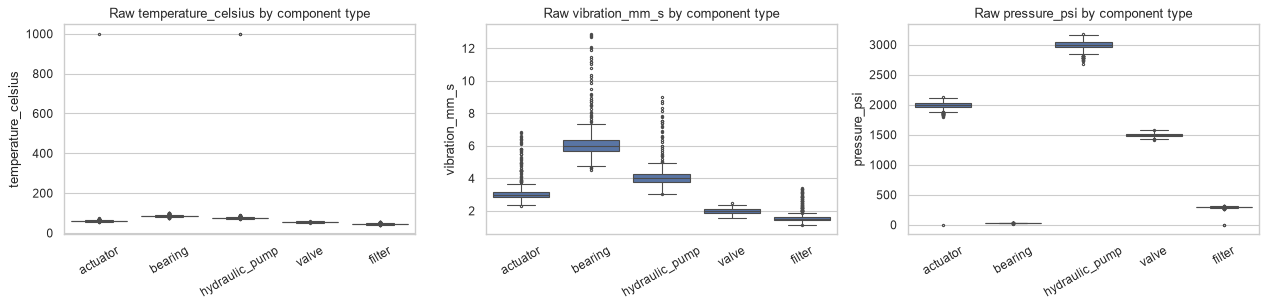

In [35]:
display(sensors.groupby(sensors["component_id"].map(components.set_index("component_id")["component_type"]))[SENSORS]
        .median().round(1).rename_axis("component_type (median)"))

plot_df = sensors.merge(components[["component_id", "component_type"]], on="component_id", how="left")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, s in zip(axes, SENSORS):
    sns.boxplot(data=plot_df, x="component_type", y=s, ax=ax, fliersize=2)
    ax.set(title=f"Raw {s} by component type", xlabel="", ylabel=s)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

## 2. Cleaning
Every dropped or changed row is logged in `findings`.

### Sensor readings
- Rows without a component or cycle, and orphan components, are dropped.
- Duplicate (`component_id`, `flight_cycle`) rows are merged by averaging the sensors.
- Sensor glitches are handled in section 4, once each component's lives (before/after replacement) are known.

In [36]:
SENSOR_KEY = ["component_id", "flight_cycle"]
n0 = len(sensors)

bad_key = sensors[SENSOR_KEY].isna().any(axis=1)
if bad_key.any():
    log("sensors", "Missing component_id or flight_cycle", bad_key.sum(), "Dropped")
sensors = sensors[~bad_key]

orphan = ~sensors["component_id"].isin(components["component_id"])
if orphan.any():
    log("sensors", "component_id not in components", orphan.sum(), "Dropped")
sensors = sensors[~orphan].copy()
sensors["flight_cycle"] = sensors["flight_cycle"].astype(int)

dup_rows = sensors[sensors.duplicated(SENSOR_KEY, keep=False)]
if len(dup_rows):
    n_conflict = (dup_rows.groupby(SENSOR_KEY)[SENSORS].nunique(dropna=False) > 1).any(axis=1).sum()
    log("sensors", "Duplicate (component, cycle) rows", sensors.duplicated(SENSOR_KEY).sum(),
        f"Merged by averaging sensors ({n_conflict} keys had conflicting values)")
    keep_cols = [c for c in sensors if c not in SENSOR_KEY and c not in surrogate_ids(sensors, SENSOR_KEY)]
    agg = {c: "mean" if c in SENSORS else "min" if c == TS_COL else "first" for c in keep_cols}
    sensors = sensors.groupby(SENSOR_KEY, as_index=False).agg(agg)

sensors = sensors.sort_values(SENSOR_KEY).reset_index(drop=True)

print(f"sensors: {n0:,} -> {len(sensors):,} rows")

[sensors] Duplicate (component, cycle) rows: 15 -> Merged by averaging sensors (0 keys had conflicting values)
sensors: 5,015 -> 5,000 rows


### Maintenance events
- Event types are normalised (`" Unscheduled"`, `"UNSCHEDULED"` → `unscheduled`).
- Events with no cycle get one from their date: the last reading of that component at or before the event.
- Orphan components, events still without a cycle, and duplicate events are dropped.

In [37]:
n0 = len(maint)
raw_type = maint[EVENT_TYPE_COL].astype(str).str.strip().str.lower()
maint["event_type"] = np.select(
    [raw_type.str.contains("unsched"), raw_type.str.contains("sched")], ["unscheduled", "scheduled"], default="other"
)
print("raw labels -> event_type:\n", pd.crosstab(maint[EVENT_TYPE_COL].astype(str), maint["event_type"]), sep="")
if (maint["event_type"] == "other").any():
    log("maint", "Event type neither scheduled nor unscheduled", (maint["event_type"] == "other").sum(), "Kept as 'other'")

orphan = ~maint["component_id"].isin(components["component_id"])
if orphan.any():
    log("maint", "component_id not in components", orphan.sum(), "Dropped")
maint = maint[~orphan].copy()

if "flight_cycle" not in maint:
    maint["flight_cycle"] = np.nan
need = maint["flight_cycle"].isna()
if need.any() and EV_DATE_COL and TS_COL:
    left = maint.loc[need & maint[EV_DATE_COL].notna(), ["component_id", EV_DATE_COL]].reset_index().sort_values(EV_DATE_COL)
    right = (sensors[["component_id", TS_COL, "flight_cycle"]].dropna(subset=[TS_COL])
             .sort_values(TS_COL).rename(columns={"flight_cycle": "cycle_from_date"}))
    m = pd.merge_asof(left, right, left_on=EV_DATE_COL, right_on=TS_COL, by="component_id", direction="backward")
    maint.loc[m["index"], "flight_cycle"] = m["cycle_from_date"].to_numpy()
    log("maint", "Missing flight_cycle", m["cycle_from_date"].notna().sum(), "Filled from event date (last reading at or before it)")

still = maint["flight_cycle"].isna()
if still.any():
    log("maint", "No flight_cycle and no usable date", still.sum(), "Dropped")
maint = maint[~still].copy()
maint["flight_cycle"] = maint["flight_cycle"].astype(int)

dup = maint.drop(columns=surrogate_ids(maint, None)).duplicated()
if dup.any():
    log("maint", "Duplicate events", dup.sum(), "Dropped")
maint = maint[~dup]

print(f"maint: {n0:,} -> {len(maint):,} rows")
maint["event_type"].value_counts().to_frame()

raw labels -> event_type:
event_type        scheduled  unscheduled
maintenance_type                        
SCHEDULED                60            0
Scheduled                60            0
UNSCHEDULED               0            4
Unscheduled               0            4
scheduled                68            0
unscheduled               0            3
[maint] component_id not in components: 1 -> Dropped
[maint] Missing flight_cycle: 2 -> Filled from event date (last reading at or before it)
maint: 199 -> 198 rows


,count
event_type,
scheduled,187
unscheduled,11


## 3. Target: `tgt_fail_30`
A failure (unscheduled event) at cycle *f* ends a component **life**; readings after *f* belong to the replacement part (`life` + 1).
For each reading at cycle *t*:
- `next_fail` = first failure cycle > *t*; `tgt_cycles_to_failure` = `next_fail` − *t* (analysis only, never a feature);
- `tgt_fail_30` = 1 if `next_fail` − *t* ≤ 30; 0 if no failure in *t+1 … t+30* **and** those cycles are observed; otherwise NaN (censored);
- rows at the failure cycle itself (`at_failure`) are not used: the failure is already happening.

In [38]:
fails = (maint.loc[maint["event_type"] == "unscheduled", ["component_id", "flight_cycle"]]
         .drop_duplicates().rename(columns={"flight_cycle": "fail_cycle"}))
print(f"{len(fails)} unscheduled failures on {fails['component_id'].nunique()} components")

# Pair every reading with every failure of its component, then summarise per reading
pairs = sensors[SENSOR_KEY].merge(fails, on="component_id")
pairs["next_fail"] = pairs["fail_cycle"].where(pairs["fail_cycle"] > pairs["flight_cycle"])
pairs["prev_fail"] = pairs["fail_cycle"].where(pairs["fail_cycle"] < pairs["flight_cycle"])
pairs["at_failure"] = pairs["fail_cycle"] == pairs["flight_cycle"]
life_info = pairs.groupby(SENSOR_KEY).agg(
    next_fail=("next_fail", "min"), prev_fail=("prev_fail", "max"),
    life=("prev_fail", "count"), at_failure=("at_failure", "any"),
)

sensors = sensors.drop(columns=[c for c in life_info if c in sensors]).merge(
    life_info.reset_index(), on=SENSOR_KEY, how="left", validate="one_to_one")
sensors["life"] = sensors["life"].fillna(0).astype(int)
sensors["at_failure"] = sensors["at_failure"].fillna(False).astype(bool)

obs_end = sensors.groupby("component_id")["flight_cycle"].transform("max")
sensors["tgt_cycles_to_failure"] = sensors["next_fail"] - sensors["flight_cycle"]
is_pos = sensors["tgt_cycles_to_failure"] <= HORIZON
is_known = sensors["next_fail"].notna() | (sensors["flight_cycle"] + HORIZON <= obs_end)
sensors["tgt_fail_30"] = np.where(is_pos, 1.0, np.where(is_known, 0.0, np.nan))

# Failures with no sensor rows in the 30 cycles before them cannot be learned from
covered = sensors.loc[is_pos].groupby("component_id")["next_fail"].nunique().sum()
if covered < len(fails):
    log("target", "Failures with no readings in the 30 cycles before them", len(fails) - covered, "Not learnable; excluded")
log("target", f"Censored rows (no failure seen and next {HORIZON} cycles not observed)", sensors["tgt_fail_30"].isna().sum(),
    "Label unknown; excluded from modeling")
log("target", "Rows at the failure cycle", sensors["at_failure"].sum(), "Excluded from modeling")
print("components with >1 life (replaced and kept reporting):", (sensors.groupby("component_id")["life"].max() > 0).sum())
sensors["tgt_fail_30"].value_counts(dropna=False).to_frame().assign(pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2))

11 unscheduled failures on 11 components
[target] Censored rows (no failure seen and next 30 cycles not observed): 1,262 -> Label unknown; excluded from modeling
[target] Rows at the failure cycle: 11 -> Excluded from modeling
components with >1 life (replaced and kept reporting): 6


,count,pct
tgt_fail_30,,
0.0,3408,68.16
NaN,1262,25.24
1.0,330,6.60


## 4. Features
Grain stays 1 row per (`component_id`, `flight_cycle`); all features are computed **within the same component life** and use only cycles ≤ *t*.
- **Missing readings and glitches:** forward-filled from the previous cycle (causal); `sen_n_missing` counts the gaps at *t*.
- **Baseline normalisation:** each life's first `BASELINE_CYCLES` readings define its healthy mean and std.
  `sen_<s>_z` = (value − baseline mean) / baseline std and `sen_<s>_pct` = value / baseline mean − 1.
  This removes the scale difference between component types. Rows inside the baseline window are not modelled (their baseline uses cycles after *t*).
- **Trends:** rolling mean, std and OLS slope of each z-score over the last 5 and 10 cycles; `sen_health_max_z` = largest |z| across sensors.
- **Maintenance history:** number of scheduled events before cycle *t* and cycles since the last one.

**Not used as features (leakage or confounding):**
- any maintenance event at or after cycle *t* (the unscheduled event *is* the target; downtime/cost/action are only known after it);
- `total_flight_hours`: a snapshot taken at the end of the data, so it includes hours flown after *t*;
- end-of-data component fields (e.g. status, an installation date overwritten by the replacement);
- statistics over a component's full series (they include the degradation period);
- `flight_cycle` / `cyc_in_life` (cycle count): only the last ~30 cycles of a non-failing component are censored, so a high cycle count marks failures by construction. Checked in section 5.

### Glitches
A glitch becomes NaN (then forward-filled like any missing reading). Both rules use only earlier readings of the same life, so they also work at prediction time:
- physically impossible values (negative vibration or pressure, temperature below −60 °C);
- a jump of more than 50% from the median of the previous 5 readings.

A global outlier rule (e.g. 6 standard deviations) is not used: real degradation also produces extreme values.
Rules are applied within a life because a replaced part legitimately drops back to normal values.

In [39]:
LIFE_KEY = ["component_id", "life"]
sensors = sensors.sort_values(SENSOR_KEY).reset_index(drop=True)

GLITCH_JUMP = 0.5
glitches = {}
for s in SENSORS:
    prev_median = sensors.groupby(LIFE_KEY)[s].transform(lambda x: x.shift(1).rolling(5, min_periods=3).median())
    impossible = sensors[s] < (-60 if s.startswith("temp") else 0)
    jump = (sensors[s] / prev_median - 1).abs() > GLITCH_JUMP
    bad = impossible | jump
    glitches[s] = sensors.loc[bad, s].round(1).tolist()
    if bad.any():
        log("sensors", f"Glitch in {s} (impossible value or >50% jump vs previous 5 readings)", bad.sum(), "Set to NaN")
    sensors.loc[bad, s] = np.nan
    if bad.any():
        print(f"  removed values: {glitches[s][:10]}; rows in the 30 cycles before a failure: {(bad & (sensors['tgt_fail_30'] == 1)).sum()}")

[sensors] Glitch in temperature_celsius (impossible value or >50% jump vs previous 5 readings): 3 -> Set to NaN
  removed values: [999.0, 999.0, 999.0]; rows in the 30 cycles before a failure: 0
[sensors] Glitch in pressure_psi (impossible value or >50% jump vs previous 5 readings): 3 -> Set to NaN
  removed values: [-1.0, -1.0, -1.0]; rows in the 30 cycles before a failure: 0


In [40]:
sensors["cyc_in_life"] = sensors.groupby(LIFE_KEY).cumcount()

sensors["sen_n_missing"] = sensors[SENSORS].isna().sum(axis=1)
sensors[SENSORS] = sensors.groupby(LIFE_KEY)[SENSORS].ffill()

sensors["in_baseline"] = sensors["cyc_in_life"] < BASELINE_CYCLES
base = sensors[sensors["in_baseline"]].groupby(LIFE_KEY)[SENSORS].agg(["mean", "std"])
base.columns = [f"{s}_base_{stat}" for s, stat in base.columns]
sensors = sensors.drop(columns=[c for c in base if c in sensors]).merge(
    base.reset_index(), on=LIFE_KEY, how="left", validate="many_to_one")

for s, k in SHORT.items():
    mu, sd = sensors[f"{s}_base_mean"], sensors[f"{s}_base_std"]
    sensors[f"sen_{k}_z"] = (sensors[s] - mu) / sd.where(sd > 0)
    sensors[f"sen_{k}_pct"] = sensors[s] / mu - 1
sensors["sen_health_max_z"] = sensors[[f"sen_{k}_z" for k in SHORT.values()]].abs().max(axis=1, skipna=False)

def rolling_slope(y, w):
    x = np.arange(w) - (w - 1) / 2
    return y.rolling(w, min_periods=w).apply(lambda v: x @ v / (x @ x), raw=True)

by_life = sensors.groupby(LIFE_KEY)
for k in SHORT.values():
    z = f"sen_{k}_z"
    for w in WINDOWS:
        sensors[f"{z}_mean{w}"] = by_life[z].transform(lambda y: y.rolling(w, min_periods=w).mean())
        sensors[f"{z}_std{w}"] = by_life[z].transform(lambda y: y.rolling(w, min_periods=w).std())
        sensors[f"{z}_slope{w}"] = by_life[z].transform(lambda y: rolling_slope(y, w))
sensors["sen_health_mean5"] = by_life["sen_health_max_z"].transform(lambda y: y.rolling(5, min_periods=5).mean())

# Scheduled maintenance strictly before cycle t
sched = maint.loc[maint["event_type"] == "scheduled", ["component_id", "flight_cycle"]].rename(columns={"flight_cycle": "ev_cycle"})
past = sensors[SENSOR_KEY].merge(sched, on="component_id")
past = past[past["ev_cycle"] < past["flight_cycle"]]
hist = past.groupby(SENSOR_KEY).agg(mnt_n_sched_before=("ev_cycle", "size"), last_sched=("ev_cycle", "max")).reset_index()
sensors = sensors.drop(columns=[c for c in hist if c in sensors and c not in SENSOR_KEY]).merge(
    hist, on=SENSOR_KEY, how="left", validate="one_to_one")
sensors["mnt_n_sched_before"] = sensors["mnt_n_sched_before"].fillna(0).astype(int)
sensors["mnt_cyc_since_sched"] = sensors["flight_cycle"] - sensors.pop("last_sched")  # NaN = none yet

SEN_COLS = [c for c in sensors if c.startswith("sen_")]
print(f"{len(SEN_COLS)} sensor features; rows in baseline window: {sensors['in_baseline'].sum():,}")

27 sensor features; rows in baseline window: 545


### Join static context
Components and aircraft are pre-aggregated already (1 row per key), so they join many-to-one onto the reading grain.
`FLEET_EXCLUDE` lists fleet columns that are not known at prediction time.

In [41]:
def checked_merge(left, right, on, validate="many_to_one", name=""):
    """Left join that asserts no row explosion and logs counts."""
    out = left.merge(right, on=on, how="left", validate=validate, indicator=True)
    unmatched = (out.pop("_merge") == "left_only").sum()
    print(f"{name}: {len(left):,} -> {len(out):,} rows | unmatched: {unmatched:,}")
    assert len(out) == len(left)
    return out

FLEET_EXCLUDE = ["total_flight_hours"]
fleet_ctx = fleet.drop(columns=[c for c in fleet if c in FLEET_EXCLUDE or pd.api.types.is_datetime64_any_dtype(fleet[c])])
fleet_ctx = fleet_ctx.set_index("aircraft_id").add_prefix("ac_").reset_index()
comp_ctx = components[["component_id", "aircraft_id", "component_type"]].rename(columns={"component_type": "cmp_type"})

features = sensors.drop(columns=[c for c in sensors if c.startswith(("ac_", "cmp_")) or c == "aircraft_id"])
features = checked_merge(features, comp_ctx, on="component_id", name="readings + components")
features = checked_merge(features, fleet_ctx, on="aircraft_id", name="readings + fleet")
assert not features.duplicated(SENSOR_KEY).any()

print("Columns not used as features (review for leakage):")
print("  fleet:", [c for c in fleet if f"ac_{c}" not in fleet_ctx and c != "aircraft_id"])
print("  components:", [c for c in components if c not in ("component_id", "aircraft_id", "component_type")])
print("  maint:", [c for c in maint if c not in ("component_id", "flight_cycle", "event_type")])
features.shape

readings + components: 5,000 -> 5,000 rows | unmatched: 0
readings + fleet: 5,000 -> 5,000 rows | unmatched: 0
Columns not used as features (review for leakage):
  fleet: ['total_flight_hours']
  components: ['installation_date', 'status']
  maint: ['event_id', 'maintenance_type', 'action', 'downtime_hours', 'aircraft_id', 'event_date']


(5000, 54)

### Sensor drift before failure
Each line is one failure, aligned on its failure cycle. The grey band is the 5–95% range of healthy rows (label 0).

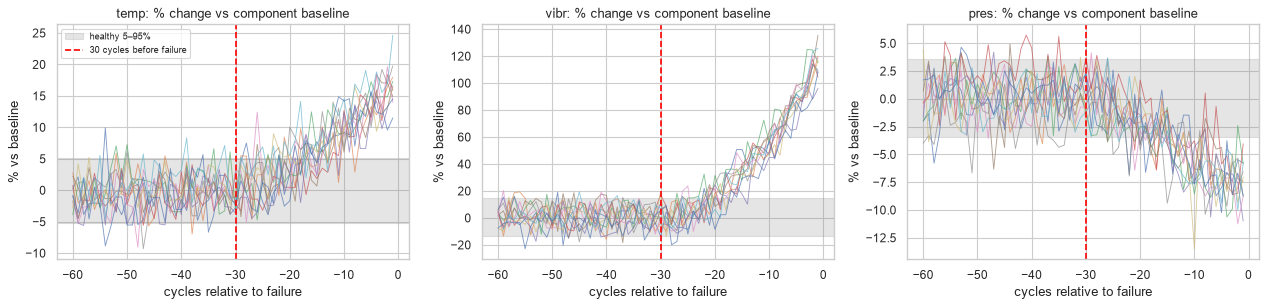

In [42]:
pre = features[features["next_fail"].notna() & (features["tgt_cycles_to_failure"] <= 2 * HORIZON)]
healthy = features[(features["tgt_fail_30"] == 0) & ~features["in_baseline"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, k in zip(axes, SHORT.values()):
    col = f"sen_{k}_pct"
    lo, hi = healthy[col].quantile([0.05, 0.95])
    ax.axhspan(lo * 100, hi * 100, color="grey", alpha=0.2, label="healthy 5–95%")
    for _, g in pre.groupby(["component_id", "next_fail"]):
        ax.plot(-g["tgt_cycles_to_failure"], g[col] * 100, lw=0.8, alpha=0.7)
    ax.axvline(-HORIZON, color="red", ls="--", label=f"{HORIZON} cycles before failure")
    ax.set(title=f"{k}: % change vs component baseline", xlabel="cycles relative to failure", ylabel="% vs baseline")
axes[0].legend(fontsize=8)
plt.tight_layout()

## 5. Leakage checks
1. Column names that suggest after-the-fact information.
2. Single-feature ROC-AUC on the modeling rows: anything near 1.0 is either a leak or a design artefact.

In [43]:
SUSPECT = re.compile(r"(fail|rul|remaining|target|label|next|status|replac|removal|downtime|cost|outcome|result|total)")
print("Suspicious raw column names:")
for name, df in dfs.items():
    hits = [c for c in df if SUSPECT.search(c)]
    if hits:
        print(f"  {name}: {hits}")

from sklearn.metrics import roc_auc_score
is_model_row = features["tgt_fail_30"].notna() & ~features["at_failure"] & ~features["in_baseline"]
rows = features[is_model_row]
check_cols = SEN_COLS + ["mnt_n_sched_before", "mnt_cyc_since_sched", "flight_cycle", "cyc_in_life"] + \
             [c for c in rows if c.startswith("ac_") and pd.api.types.is_numeric_dtype(rows[c])]
single_auc = pd.Series({
    c: roc_auc_score(rows["tgt_fail_30"], rows[c].fillna(rows[c].median())) for c in check_cols
}).rename("roc_auc").to_frame()
single_auc["strength"] = (single_auc["roc_auc"] - 0.5).abs() + 0.5  # direction-free
single_auc = single_auc.sort_values("strength", ascending=False)
display(single_auc.head(15).round(3))
for c in ("flight_cycle", "cyc_in_life"):
    print(f"{c}: single-feature AUC {single_auc.loc[c, 'strength']:.3f} -> excluded (censoring artefact, see section 4)")

Suspicious raw column names:
  fleet: ['total_flight_hours']
  components: ['status']
  maint: ['downtime_hours']


,roc_auc,strength
cyc_in_life,0.939,0.939
flight_cycle,0.939,0.939
sen_health_mean5,0.874,0.874
sen_temp_z_mean5,0.858,0.858
sen_vibr_z_mean5,0.854,0.854
sen_health_max_z,0.854,0.854
sen_vibr_z_std10,0.852,0.852
sen_pres_z_mean5,0.149,0.851
sen_vibr_z,0.851,0.851
sen_vibr_pct,0.851,0.851


flight_cycle: single-feature AUC 0.939 -> excluded (censoring artefact, see section 4)
cyc_in_life: single-feature AUC 0.939 -> excluded (censoring artefact, see section 4)


## 6. Model: will the component fail within 30 cycles?
- **Rows:** labelled, not at the failure cycle, past the baseline window.
- **Feature sets:** `sensors` (baseline-normalised sensors and trends) and `sensors + context` (adds maintenance history, component type, aircraft attributes).
- **Validation:** `StratifiedGroupKFold` by `component_id`. Adjacent cycles of the same component are nearly identical, so a random row split would put the same degradation curve in train and validation.
  With ~11 failures, out-of-fold scores over all components are more stable than one small test split.
- **Metric:** AUC-PR on pooled out-of-fold predictions (a random model scores the positive rate), plus ROC-AUC.
- **Models:** a no-training heuristic (`sen_health_mean5`), logistic regression, LightGBM (small trees, fixed parameters).

In [44]:
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TARGET = "tgt_fail_30"
log("model_df", "Rows in the baseline window (first cycles of each life)", (features["in_baseline"] & features[TARGET].notna()).sum(),
    "Excluded from modeling")
model_df = features[is_model_row].reset_index(drop=True)
y = model_df[TARGET].astype(int)

cat_cols = ["cmp_type"] + [c for c in model_df if c.startswith("ac_") and not pd.api.types.is_numeric_dtype(model_df[c])]
dummies = pd.get_dummies(model_df[cat_cols], prefix=cat_cols, dtype=int)
model_df = pd.concat([model_df, dummies], axis=1)
num_ctx = [c for c in model_df if c.startswith("ac_") and pd.api.types.is_numeric_dtype(model_df[c]) and c not in dummies]
CONTEXT_COLS = ["mnt_n_sched_before", "mnt_cyc_since_sched"] + num_ctx + list(dummies.columns)
FEATURE_SETS = {"sensors": SEN_COLS, "sensors + context": SEN_COLS + CONTEXT_COLS}
assert not model_df[SEN_COLS].isna().any().any(), "sensor features should be complete after the baseline window"

n_fail_comp = model_df.loc[y == 1, "component_id"].nunique()
N_SPLITS = min(5, n_fail_comp)
cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
          .split(model_df, y, groups=model_df["component_id"]))

print({k: len(v) for k, v in FEATURE_SETS.items()}, "features")
print(f"{len(model_df):,} rows, {model_df['component_id'].nunique()} components, "
      f"{y.sum()} positive rows ({y.mean():.1%}) from {n_fail_comp} failing components")
pd.DataFrame([
    {"fold": i, "val_components": model_df.loc[va, "component_id"].nunique(),
     "val_failing_components": model_df.loc[va][y.iloc[va] == 1]["component_id"].nunique(),
     "val_rows": len(va), "val_positive_%": round(y.iloc[va].mean() * 100, 1)}
    for i, (_, va) in enumerate(cv)
]).set_index("fold")

[model_df] Rows in the baseline window (first cycles of each life): 510 -> Excluded from modeling
{'sensors': 27, 'sensors + context': 41} features
3,227 rows, 50 components, 330 positive rows (10.2%) from 11 failing components


,val_components,val_failing_components,val_rows,val_positive_%
fold,,,,
0,10,2,653,9.2
1,10,2,650,9.2
2,10,2,646,9.3
3,10,2,618,9.7
4,10,3,660,13.6


,model,feature_set,n_features,oof_auc_pr,oof_roc_auc,fold_auc_pr_mean,fold_auc_pr_std
0,random baseline,-,0,0.1023,0.5000,NaN,NaN
1,heuristic: sen_health_mean5,-,1,0.7304,0.8738,0.7402,0.0555
2,logistic regression,sensors,27,0.7602,0.8863,0.7775,0.0298
3,LightGBM,sensors,27,0.7747,0.8730,0.7751,0.0153
4,logistic regression,sensors + context,41,0.7273,0.8920,0.7449,0.0340
5,LightGBM,sensors + context,41,0.7905,0.9091,0.7912,0.0128


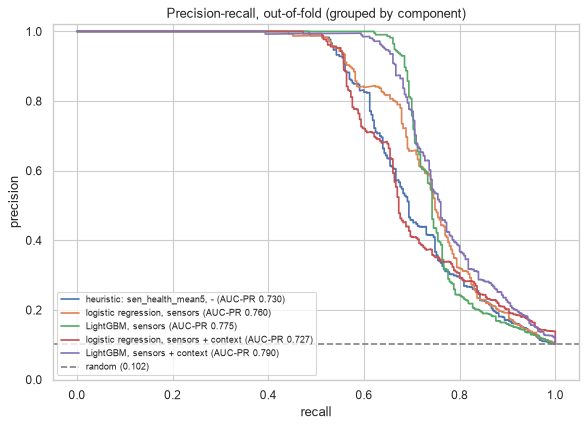

In [45]:
def make_lr():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))

def make_lgbm():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=20,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                              random_state=RANDOM_STATE, verbose=-1)

def oof_predict(make_model, cols):
    """Out-of-fold scores: each component is scored by a model that never saw it."""
    p = np.full(len(model_df), np.nan)
    for tr, va in cv:
        model = make_model().fit(model_df.loc[tr, cols], y.iloc[tr])
        p[va] = model.predict_proba(model_df.loc[va, cols])[:, 1]
    return p

preds = {("heuristic: sen_health_mean5", "-"): model_df["sen_health_mean5"].to_numpy()}
for set_name, cols in FEATURE_SETS.items():
    preds[("logistic regression", set_name)] = oof_predict(make_lr, cols)
    preds[("LightGBM", set_name)] = oof_predict(make_lgbm, cols)

def fold_auc_pr(p):
    vals = [average_precision_score(y.iloc[va], p[va]) for _, va in cv if y.iloc[va].nunique() == 2]
    return np.mean(vals), np.std(vals)

metrics = pd.DataFrame(
    [{"model": "random baseline", "feature_set": "-", "n_features": 0, "oof_auc_pr": y.mean(), "oof_roc_auc": 0.5}]
    + [{"model": m, "feature_set": fs, "n_features": len(FEATURE_SETS.get(fs, [1])),
        "oof_auc_pr": average_precision_score(y, p), "oof_roc_auc": roc_auc_score(y, p),
        "fold_auc_pr_mean": fold_auc_pr(p)[0], "fold_auc_pr_std": fold_auc_pr(p)[1]}
       for (m, fs), p in preds.items()]
).round(4)
display(metrics)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for (m, fs), p in preds.items():
    precision, recall, _ = precision_recall_curve(y, p)
    ax.plot(recall, precision, label=f"{m}, {fs} (AUC-PR {average_precision_score(y, p):.3f})")
ax.axhline(y.mean(), color="grey", ls="--", label=f"random ({y.mean():.3f})")
ax.set(title="Precision-recall, out-of-fold (grouped by component)", xlabel="recall", ylabel="precision", ylim=(0, 1.02))
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()

### Feature importance
LightGBM with every feature, fitted on all modeling rows (for interpretation only; scores above are out-of-fold).

Context features' share of total gain: 27.3%


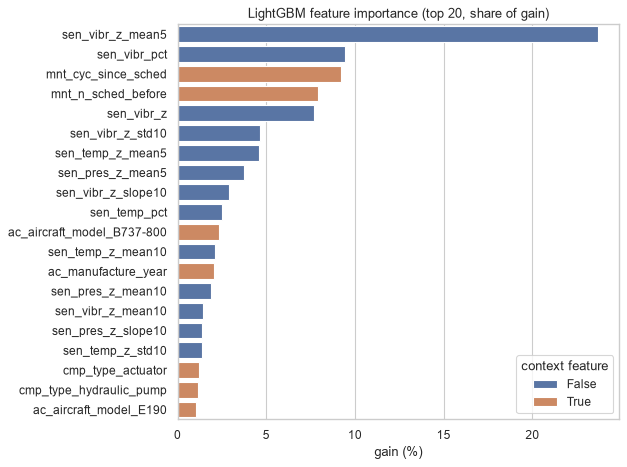

In [46]:
all_cols = FEATURE_SETS["sensors + context"]
full_lgbm = make_lgbm().fit(model_df[all_cols], y)
importance = pd.DataFrame({"feature": all_cols, "gain": full_lgbm.booster_.feature_importance("gain")})
importance["gain_%"] = (importance["gain"] / importance["gain"].sum() * 100).round(2)
importance = importance.sort_values("gain_%", ascending=False, ignore_index=True)
importance["is_context"] = importance["feature"].isin(CONTEXT_COLS)
print(f"Context features' share of total gain: {importance.loc[importance['is_context'], 'gain_%'].sum():.1f}%")

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=importance.head(20), x="gain_%", y="feature", hue="is_context", dodge=False, ax=ax)
ax.set(title="LightGBM feature importance (top 20, share of gain)", xlabel="gain (%)", ylabel="")
ax.legend(title="context feature")
plt.tight_layout()

### Component-level view: would we have caught each failure in time?
Using the best model's out-of-fold scores and the threshold that maximises F1 (chosen on the same out-of-fold scores, so slightly optimistic):
- each failure is **detected** if at least one of its 30 pre-failure cycles raises an alarm; **lead time** = cycles between the first alarm and the failure;
- a **false alarm** is an alarm on a row labelled 0; we also count healthy component lives with at least one alarm.

In [47]:
best_key = max((k for k in preds if k[0] != "heuristic: sen_health_mean5"), key=lambda k: average_precision_score(y, preds[k]))
score = preds[best_key]
precision, recall, thresholds = precision_recall_curve(y, score)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
THRESHOLD = thresholds[np.argmax(f1)]
print(f"best model: {best_key} | threshold {THRESHOLD:.3f} | row precision {precision[np.argmax(f1)]:.2f}, recall {recall[np.argmax(f1)]:.2f}")

scored = model_df[["component_id", "life", "flight_cycle", "next_fail", TARGET]].assign(score=score, alarm=score >= THRESHOLD)
pos = scored[scored[TARGET] == 1]
per_failure = pos.groupby(["component_id", "next_fail"]).agg(window_rows=("alarm", "size"), alarm_rows=("alarm", "sum"))
per_failure["first_alarm_cycle"] = pos[pos["alarm"]].groupby(["component_id", "next_fail"])["flight_cycle"].min()
per_failure["lead_cycles"] = per_failure.index.get_level_values("next_fail") - per_failure["first_alarm_cycle"]
per_failure["detected"] = per_failure["alarm_rows"] > 0
display(per_failure)

lives = scored.groupby(["component_id", "life"]).agg(fails=(TARGET, "max"), any_alarm=("alarm", "any"))
healthy_lives = lives[lives["fails"] == 0]
summary = pd.Series({
    "failures detected": f"{per_failure['detected'].sum()} / {len(per_failure)}",
    "median lead time (cycles)": per_failure["lead_cycles"].median(),
    "false-alarm rate on label-0 rows": f"{scored.loc[scored[TARGET] == 0, 'alarm'].mean():.1%}",
    "healthy component lives with >=1 alarm": f"{healthy_lives['any_alarm'].sum()} / {len(healthy_lives)}",
})
summary.to_frame("value")

best model: ('LightGBM', 'sensors + context') | threshold 0.367 | row precision 0.94, recall 0.66


,,window_rows,alarm_rows,first_alarm_cycle,lead_cycles,detected
component_id,next_fail,,,,,
C003,95.0,30,18,77,18.0,True
C004,92.0,30,18,74,18.0,True
C006,100.0,30,21,78,22.0,True
C012,98.0,30,16,81,17.0,True
C022,100.0,30,20,80,20.0,True
C023,100.0,30,18,82,18.0,True
C030,100.0,30,25,75,25.0,True
C033,88.0,30,20,68,20.0,True
C038,100.0,30,23,77,23.0,True


,value
failures detected,11 / 11
median lead time (cycles),20.0
false-alarm rate on label-0 rows,0.5%
healthy component lives with >=1 alarm,6 / 39


### Cost-based threshold: an AOG costs much more than an inspection
The F1 threshold above treats a missed failure and a false alarm as equally bad. Here the threshold minimises expected cost instead:

**expected cost = `COST_AOG` × missed failures + `COST_INSPECTION` × unnecessary inspections**

- A failure counts as **caught** only if an alarm fires at least `MIN_LEAD` cycles before it, which is the time needed to get the part and a maintenance slot. A later alarm does not prevent the AOG.
- An **unnecessary inspection** is an alarm on a healthy row (label 0). While the alarm stays on, the part is re-inspected every `REINSPECT_CYCLES` cycles, so a long false alarm costs more than a short one.
- Costs are in units of one inspection, so only their ratio matters. Replace them with the business's figures.
- Each model is compared at its own cheapest threshold, i.e. where it would actually be operated. If several thresholds tie, the middle of that range is used (most margin both ways); if models tie, the simpler one wins.
- The threshold is chosen on the same out-of-fold scores it is scored on, and there are only ~11 failures, so the result is optimistic. The "hardest failures" table shows how much margin is left.

In [48]:
COST_AOG = 100.0       # cost of one missed failure (AOG), in units of one inspection
COST_INSPECTION = 1.0  # cost of one unnecessary inspection
MIN_LEAD = 5           # cycles of warning needed to plan the repair
REINSPECT_CYCLES = 10  # a part with a standing false alarm is re-inspected every N cycles

# Rows in (component, life, cycle) order so consecutive alarms can be grouped into episodes
order = model_df.sort_values(["component_id", "life", "flight_cycle"]).index.to_numpy()
srt = model_df.loc[order, ["component_id", "life", "flight_cycle", "next_fail", TARGET]]
same_life_as_prev = ((srt["component_id"] == srt["component_id"].shift()) & (srt["life"] == srt["life"].shift())).to_numpy()
is_neg = (srt[TARGET] == 0).to_numpy()
actionable = ((srt[TARGET] == 1) & (srt["next_fail"] - srt["flight_cycle"] >= MIN_LEAD)).to_numpy()
fail_key = (srt["component_id"] + " @ cycle " + srt["next_fail"].astype("Int64").astype(str)).to_numpy()
all_failures = set(fail_key[(srt[TARGET] == 1).to_numpy()])
uncatchable = all_failures - set(fail_key[actionable])
if uncatchable:
    print(f"{len(uncatchable)} failures have no reading >= {MIN_LEAD} cycles before them, so no threshold can catch them: {sorted(uncatchable)}")

def outcomes(p_sorted, thr):
    """Missed failures and unnecessary inspections for one threshold."""
    alarm = p_sorted >= thr
    missed = len(all_failures) - len(set(fail_key[actionable & alarm]))
    false_alarm = alarm & is_neg
    starts = false_alarm & ~(np.r_[False, false_alarm[:-1]] & same_life_as_prev)
    episode = np.cumsum(starts)[false_alarm]                 # episode id of every false-alarm row
    lengths = np.bincount(episode)[1:] if len(episode) else np.array([])
    inspections = int(np.ceil(lengths[lengths > 0] / REINSPECT_CYCLES).sum())
    return missed, inspections

def cost_curve(p, n=300):
    p_sorted = np.asarray(p)[order]
    thresholds = np.unique(np.quantile(p_sorted, np.linspace(0, 1, n)))
    out = pd.DataFrame([(t, *outcomes(p_sorted, t)) for t in thresholds],
                       columns=["threshold", "missed_failures", "unnecessary_inspections"])
    out["cost"] = COST_AOG * out["missed_failures"] + COST_INSPECTION * out["unnecessary_inspections"]
    return out

def cheapest(curve):
    """Lowest-cost threshold. When a range of thresholds ties, take its middle: the most margin on both sides."""
    tied = curve[curve["cost"] == curve["cost"].min()]
    return tied.iloc[len(tied) // 2]

curves, rows = {}, []
for key, p in preds.items():
    curves[key] = cost_curve(p)
    b = cheapest(curves[key])
    rows.append({"model": key[0], "feature_set": key[1], "threshold": b["threshold"],
                 "missed_failures": int(b["missed_failures"]), "unnecessary_inspections": int(b["unnecessary_inspections"]),
                 "inspections_per_1000_cycles": b["unnecessary_inspections"] / is_neg.sum() * 1000, "cost": b["cost"]})
# Ties between models go to the simpler one (heuristic, then logistic regression, then LightGBM)
cost_table = pd.DataFrame(rows).sort_values(["cost", "missed_failures"], kind="stable").reset_index(drop=True).round(3)
cost_table.to_csv("outputs/aog_cost_thresholds.csv", index=False) if os.path.isdir("outputs") else None
print(f"{len(all_failures)} failures | COST_AOG={COST_AOG:g}, COST_INSPECTION={COST_INSPECTION:g}, "
      f"MIN_LEAD={MIN_LEAD}, REINSPECT_CYCLES={REINSPECT_CYCLES}")
cost_table

11 failures | COST_AOG=100, COST_INSPECTION=1, MIN_LEAD=5, REINSPECT_CYCLES=10


,model,feature_set,threshold,missed_failures,unnecessary_inspections,inspections_per_1000_cycles,cost
0,heuristic: sen_health_mean5,-,6.188,0,0,0.000,0.0
1,logistic regression,sensors,1.000,0,0,0.000,0.0
2,LightGBM,sensors,0.986,0,0,0.000,0.0
3,logistic regression,sensors + context,0.997,0,0,0.000,0.0
4,LightGBM,sensors + context,0.913,0,1,0.345,1.0


cheapest model: heuristic: sen_health_mean5 (-) | threshold 6.1876 | missed 0 of 11 | unnecessary inspections 0
any threshold from 4.1914 to 7.5981 gives the same cost; the middle is used


,best_score_in_time,threshold,caught
C030 @ cycle 100,7.9955,6.1876,True
C038 @ cycle 100,8.0734,6.1876,True
C004 @ cycle 92,10.0203,6.1876,True


,threshold,missed_failures,unnecessary_inspections
AOG cost / inspection cost,,,
1,6.1876,0,0
10,6.1876,0,0
100,6.1876,0,0
1000,6.1876,0,0


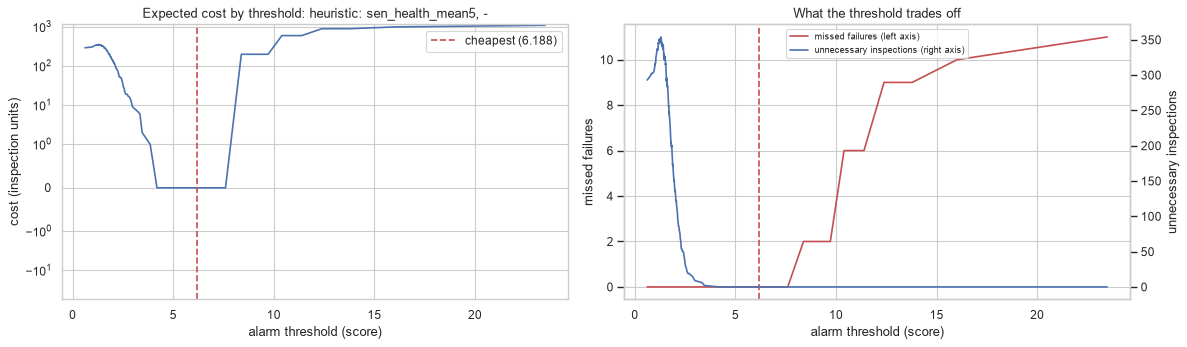

In [49]:
chosen = (cost_table.loc[0, "model"], cost_table.loc[0, "feature_set"])
curve = curves[chosen]
pick = cheapest(curve)
COST_THRESHOLD = pick["threshold"]
tied = curve.loc[curve["cost"] == curve["cost"].min(), "threshold"]
print(f"cheapest model: {chosen[0]} ({chosen[1]}) | threshold {COST_THRESHOLD:.4f} | "
      f"missed {int(pick['missed_failures'])} of {len(all_failures)} | unnecessary inspections {int(pick['unnecessary_inspections'])}")
print(f"any threshold from {tied.min():.4f} to {tied.max():.4f} gives the same cost; the middle is used")

# Margin: the failures that came closest to being missed (best score while there was still time to act)
p_chosen = np.asarray(preds[chosen])[order]
hardest = (pd.Series(p_chosen[actionable], index=fail_key[actionable]).groupby(level=0).max()
           .sort_values().rename("best_score_in_time").to_frame())
hardest["threshold"] = COST_THRESHOLD
hardest["caught"] = hardest["best_score_in_time"] >= COST_THRESHOLD
display(hardest.head(3).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
ax.plot(curve["threshold"], curve["cost"], color="C0")
ax.axvline(COST_THRESHOLD, color="C3", ls="--", label=f"cheapest ({COST_THRESHOLD:.3f})")
if chosen == best_key:
    ax.axvline(THRESHOLD, color="grey", ls=":", label=f"max F1 ({THRESHOLD:.3f})")
ax.set(title=f"Expected cost by threshold: {chosen[0]}, {chosen[1]}", xlabel="alarm threshold (score)",
       ylabel="cost (inspection units)")
ax.set_yscale("symlog", linthresh=1)  # log-like, but still shows zero
ax.legend()

ax = axes[1]
ax.plot(curve["threshold"], curve["missed_failures"], color="C3", label="missed failures (left axis)")
ax.set(title="What the threshold trades off", xlabel="alarm threshold (score)", ylabel="missed failures")
ax2 = ax.twinx()
ax2.plot(curve["threshold"], curve["unnecessary_inspections"], color="C0", label="unnecessary inspections (right axis)")
ax2.set_ylabel("unnecessary inspections")
ax2.grid(False)
ax.axvline(COST_THRESHOLD, color="C3", ls="--")
ax.legend(handles=ax.get_lines()[:1] + ax2.get_lines(), loc="upper center", fontsize=8)
plt.tight_layout()

# How the chosen threshold moves with the cost ratio
sens = []
for ratio in [1, 10, 100, 1000]:
    b = cheapest(curve.assign(cost=ratio * curve["missed_failures"] + curve["unnecessary_inspections"]))
    sens.append({"AOG cost / inspection cost": ratio, "threshold": round(b["threshold"], 4),
                 "missed_failures": int(b["missed_failures"]), "unnecessary_inspections": int(b["unnecessary_inspections"])})
pd.DataFrame(sens).set_index("AOG cost / inspection cost")

## 7. Outputs: feature table, data dictionary, metrics, findings

In [50]:
DICT = [("tgt_fail_30", "1 if an unscheduled event happens in cycles t+1..t+30; NaN if censored", "maintenance_events", "future (target)", "NaN = censored, rows excluded"),
        ("tgt_cycles_to_failure", "next failure cycle - t", "maintenance_events", "future (analysis only)", "NaN if no later failure")]
for s, k in SHORT.items():
    DICT += [(f"sen_{k}_z", f"({s} - life baseline mean) / life baseline std", f"sensor_readings.{s}", "end of cycle t", "ffill within life; baseline rows excluded"),
             (f"sen_{k}_pct", f"{s} / life baseline mean - 1", f"sensor_readings.{s}", "end of cycle t", "same as above")]
    for w in WINDOWS:
        DICT += [(f"sen_{k}_z_{stat}{w}", f"{desc} of sen_{k}_z over cycles t-{w - 1}..t", f"sensor_readings.{s}", "end of cycle t", "NaN until the window is full")
                 for stat, desc in [("mean", "Mean"), ("std", "Std"), ("slope", "OLS slope (per cycle)")]]
DICT += [("sen_health_max_z", "max |z| across the 3 sensors", "sensor_readings", "end of cycle t", "-"),
         ("sen_health_mean5", "mean of sen_health_max_z over the last 5 cycles", "sensor_readings", "end of cycle t", "-"),
         ("sen_n_missing", "number of sensors missing (or glitch) at t before forward fill", "sensor_readings", "end of cycle t", "-"),
         ("mnt_n_sched_before", "scheduled events in cycles < t", "maintenance_events", "before cycle t", "0 if none"),
         ("mnt_cyc_since_sched", "t - last scheduled event cycle", "maintenance_events", "before cycle t", "NaN if none (imputed + indicator in LR)"),
         ("cmp_type", "component type (one-hot in the model)", "components.component_type", "static", "-")]
DICT += [(c, "aircraft attribute", f"fleet_info.{c.removeprefix('ac_')}", "static", "-") for c in fleet_ctx if c != "aircraft_id"]
DICT += [(c, "EXCLUDED: end-of-data snapshot", f"fleet_info.{c}", "after prediction time", "not used") for c in FLEET_EXCLUDE if c in fleet]
DICT += [("cyc_in_life", "EXCLUDED: readings since install/replacement", "sensor_readings.flight_cycle", "end of cycle t", "confounded by censoring")]
data_dict = pd.DataFrame(DICT, columns=["variable", "definition", "source", "available_at", "null_handling"])

os.makedirs("outputs", exist_ok=True)
features.to_csv("outputs/features_component_cycle.csv", index=False)
data_dict.to_csv("outputs/aog_data_dictionary.csv", index=False)
metrics.to_csv("outputs/aog_model_metrics.csv", index=False)
print(f"saved: features {features.shape}, dictionary {len(data_dict)} rows, metrics {len(metrics)} rows")

pd.DataFrame(findings, columns=["table", "issue", "rows", "decision"])

saved: features (5000, 54), dictionary 37 rows, metrics 6 rows


,table,issue,rows,decision
0,sensors,"Duplicate (component, cycle) rows",15,Merged by averaging sensors (0 keys had confli...
1,maint,component_id not in components,1,Dropped
2,maint,Missing flight_cycle,2,Filled from event date (last reading at or bef...
3,target,Censored rows (no failure seen and next 30 cyc...,1262,Label unknown; excluded from modeling
4,target,Rows at the failure cycle,11,Excluded from modeling
5,sensors,Glitch in temperature_celsius (impossible valu...,3,Set to NaN
6,sensors,Glitch in pressure_psi (impossible value or >5...,3,Set to NaN
7,model_df,Rows in the baseline window (first cycles of e...,510,Excluded from modeling


## Summary (fill in after running on the challenge data)
- **Data quality:** see the findings table above (duplicates, glitches, label variants, orphans, missing cycles).
- **Leakage avoided:** future maintenance events, `total_flight_hours` snapshot, end-of-data component fields, full-series statistics, cycle count (censoring artefact), random row split.
- **Result:** best model and AUC-PR vs the random baseline; failures detected out of 11, median lead time, false alarms.
- **Limits:** ~11 failures is very few; per-fold scores vary a lot. Next steps: more failure history, per-type thresholds, and a cost-based threshold (cost of an AOG vs an unnecessary inspection).